In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('POWER_Point_Hourly_20260501_20260531_020d28N_085d78E_UTC.csv', skiprows=13, header=0)

In [3]:
df.head()

,YEAR,MO,DY,HR,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_LW_DWN,T2M,QV2M,RH2M
0,2026,5,1,0,0.25,1.49,26.12,20.24,94.63
1,2026,5,1,1,0.82,1.52,27.20,20.63,90.53
2,2026,5,1,2,1.44,1.56,28.76,20.37,81.70
3,2026,5,1,3,2.36,1.54,30.16,19.61,72.63
4,2026,5,1,4,3.20,1.55,31.72,18.78,63.64


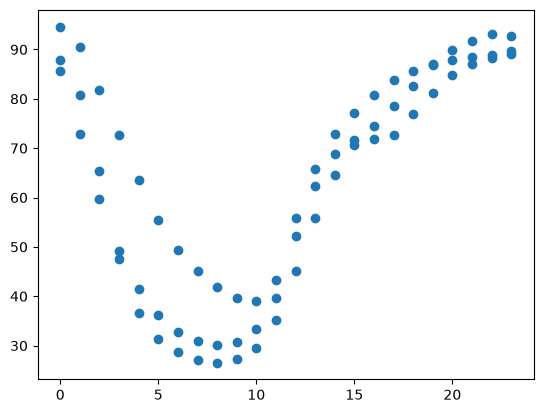

In [4]:
plt.scatter(df["HR"][0:72], df["RH2M"][0:72])

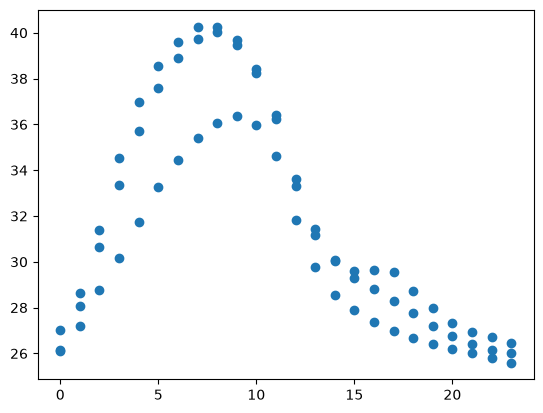

In [5]:
plt.scatter(df["HR"][0:72], df["T2M"][0:72])

In [6]:
import osmnx as ox
custom_filter = '["highway"~"footway|path|pedestrian|track|unpaved|service|residential|steps"]'

In [7]:
G = ox.graph_from_place("Odisha University of Technology and Research, Bhubaneswar", network_type="all", custom_filter=custom_filter)

In [8]:
nodes, edges = ox.graph_to_gdfs(G)

In [9]:
print(len(nodes), len(edges))

37 88


In [11]:
# edges.to_csv("edges.csv")
# nodes.to_csv("nodes.csv")
edges.to_file('campus_edges.geojson', driver="GeoJSON")
nodes.to_file('campus_nodes.geojson', driver='GeoJSON')


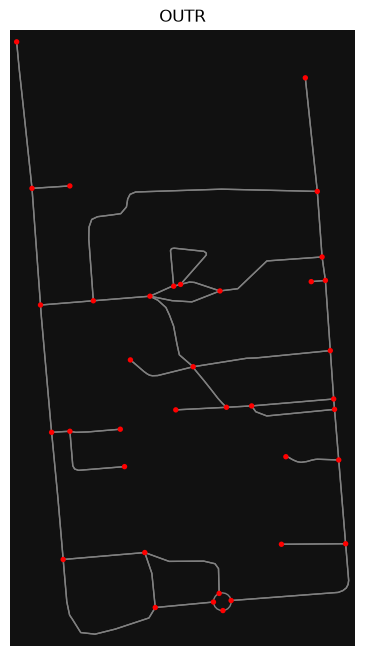

In [ ]:
fig, ax = ox.plot_graph(G, node_color='red', edge_color='gray', node_size=15, show=False, close=False)
plt.title("OUTR")
plt.show()

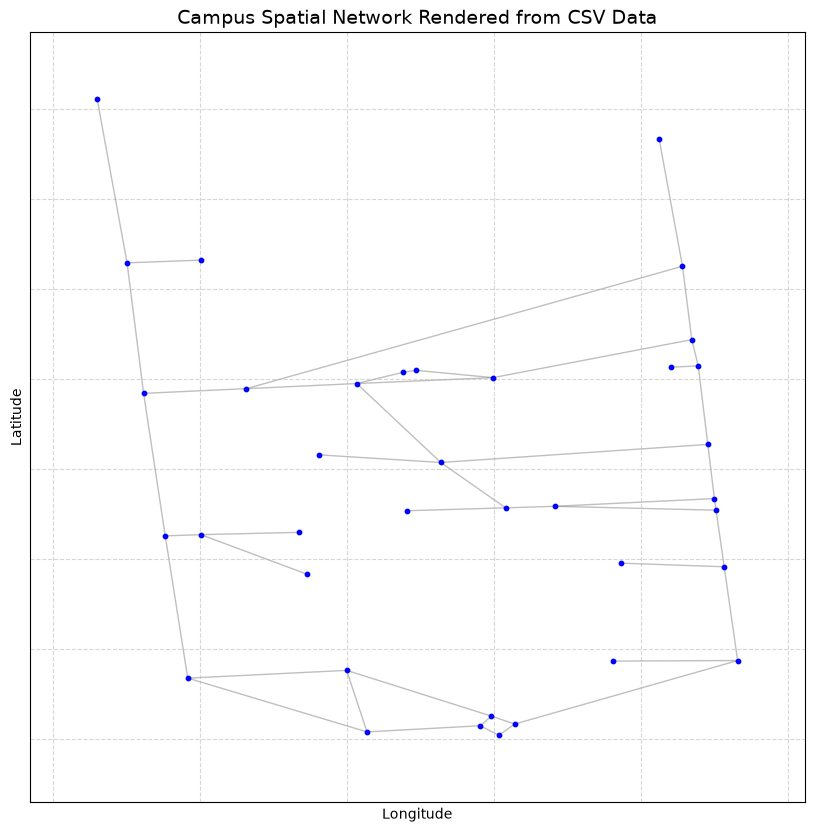

In [ ]:
import pandas as pd
import networkx as nx

# 1. Load your saved CSVs
nodes_df = pd.read_csv("nodes.csv")
edges_df = pd.read_csv("edges.csv")

# 2. Rebuild the NetworkX graph from the edge list
# Assuming columns 'u' and 'v' represent start and end node IDs
G_from_csv = nx.from_pandas_edgelist(edges_df, source='u', target='v', edge_attr=['length', 'highway'])

# 3. Extract node positions (lat, lon) for accurate spatial layout if available
# If your nodes_df has 'y' (latitude) and 'x' (longitude) columns:
pos = {row['osmid']: (row['x'], row['y']) for _, row in nodes_df.iterrows()}

# 4. Plot using Matplotlib
plt.figure(figsize=(10, 10))
nx.draw_networkx_nodes(G_from_csv, pos, node_size=10, node_color='blue')
nx.draw_networkx_edges(G_from_csv, pos, alpha=0.5, edge_color='gray')

plt.title("Campus Spatial Network Rendered from CSV Data", fontsize=14)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

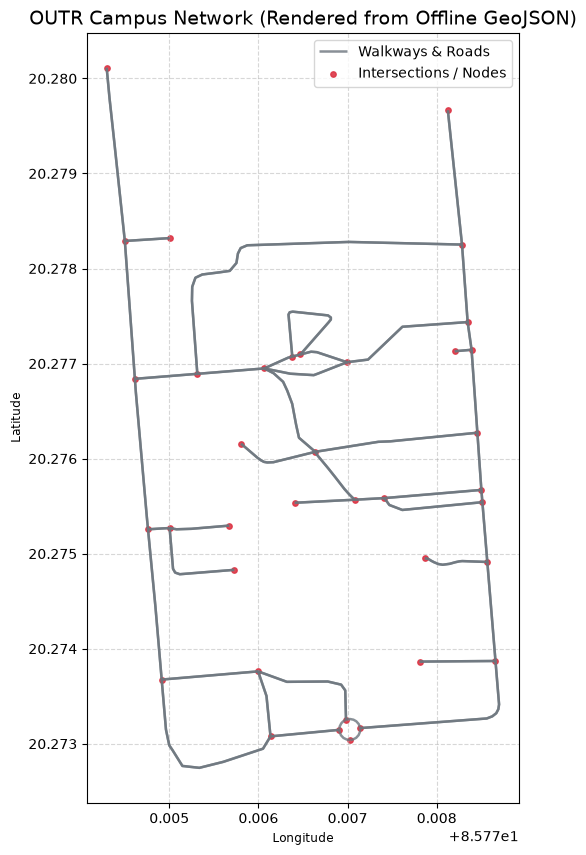

In [16]:
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Load your offline GeoJSON files
edges_gdf = gpd.read_file("campus_edges.geojson")
nodes_gdf = gpd.read_file("campus_nodes.geojson")
# If you also have nodes:
# nodes_gdf = gpd.read_file("campus_nodes.geojson")

# 2. Plot using GeoPandas (which natively understands curved LINESTRINGs)
fig, ax = plt.subplots(figsize=(10, 10))

# Plot the pathway edges
edges_gdf.plot(
    ax=ax, 
    color='#6c757d',        # Muted gray for paths
    linewidth=1.8, 
    alpha=0.8, 
    label="Walkways & Roads"
)
nodes_gdf.plot(
    ax=ax, 
    color='#dc3545',        # Red for intersection points
    markersize=15, 
    alpha=0.9, 
    label="Intersections / Nodes"
)
# If you want to color-code them based on surface type (e.g., asphalt vs. concrete)
# edges_gdf.plot(ax=ax, column='surface', cmap='Set1', linewidth=2)

# Optional: Plot nodes on top if you have them
# nodes_gdf.plot(ax=ax, color='red', markersize=10, label="Intersections")

plt.title("OUTR Campus Network (Rendered from Offline GeoJSON)", fontsize=14)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

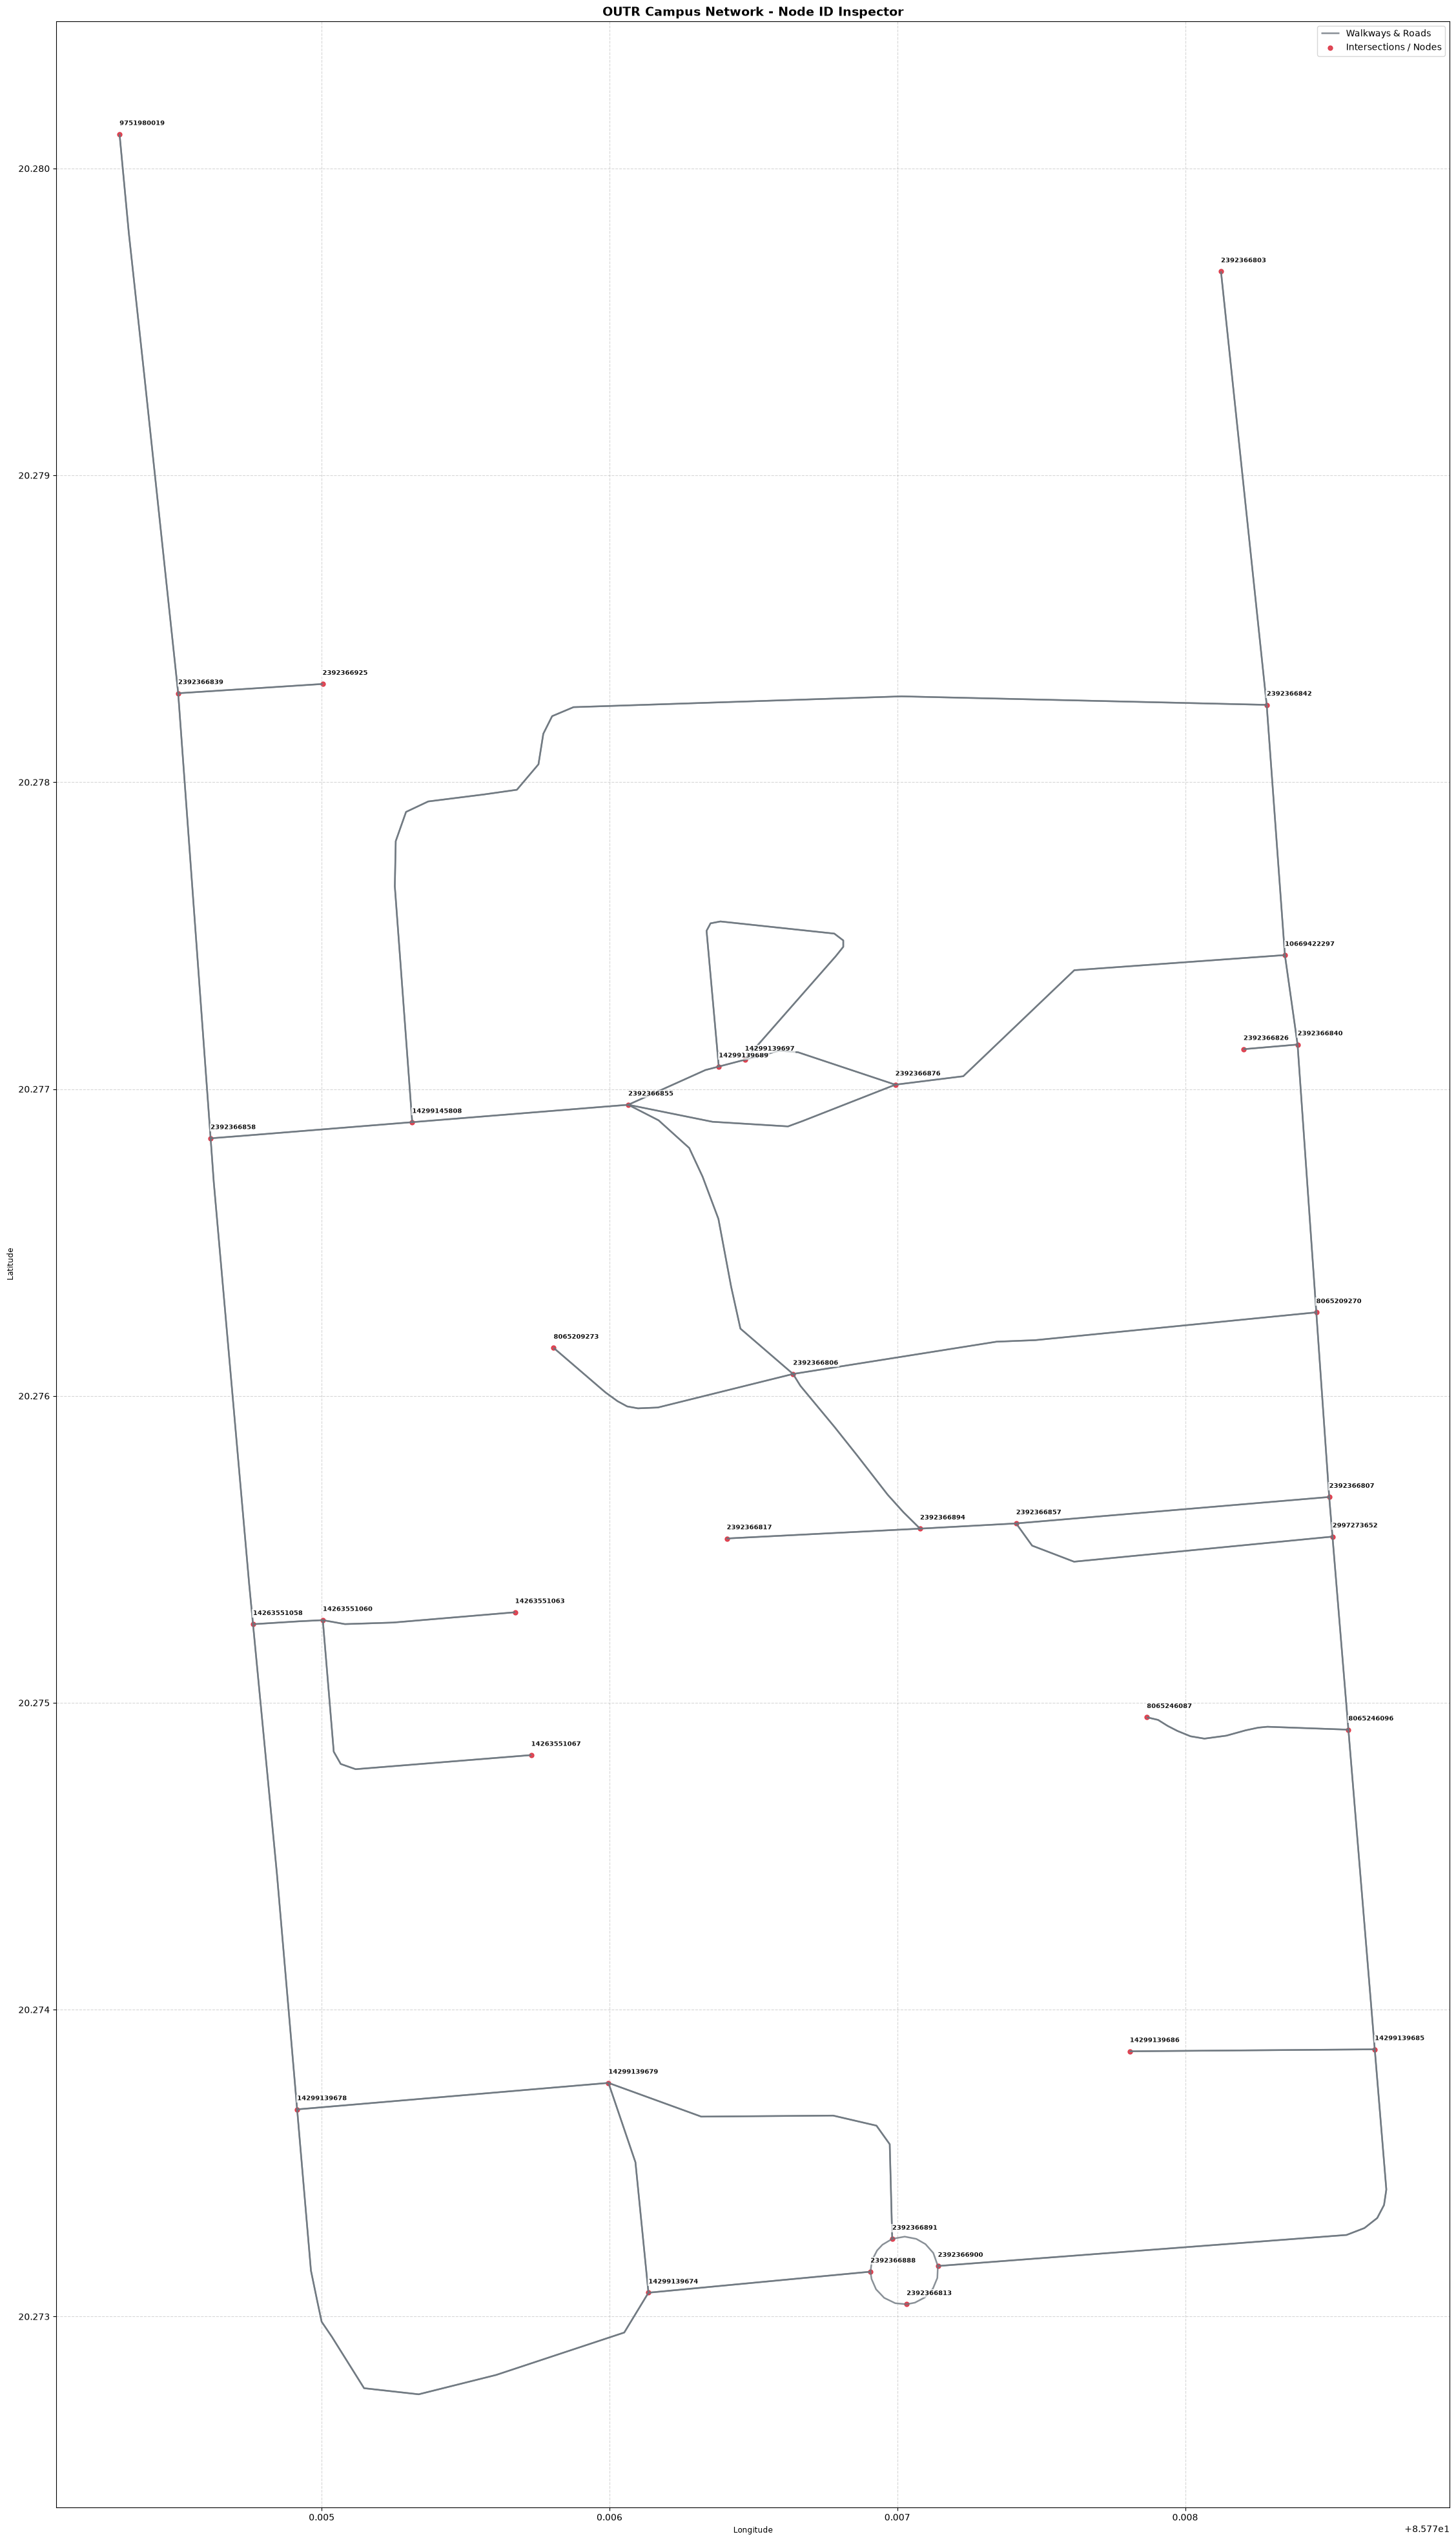

In [20]:
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Load your offline GeoJSON files
edges_gdf = gpd.read_file("campus_edges.geojson")
nodes_gdf = gpd.read_file("campus_nodes.geojson")

# 2. Set up a larger canvas so labels have room to breathe
fig, ax = plt.subplots(figsize=(50, 50))

# Plot the pathway edges
edges_gdf.plot(
    ax=ax, 
    color='#6c757d',        # Muted gray for paths
    linewidth=1.8, 
    alpha=0.8, 
    label="Walkways & Roads"
)

# Plot the intersection nodes on top
nodes_gdf.plot(
    ax=ax, 
    color='#dc3545',        # Red for intersection points
    markersize=25, 
    alpha=0.9, 
    label="Intersections / Nodes"
)

# 3. ANNOTATE EVERY NODE WITH ITS ID
for idx, row in nodes_gdf.iterrows():
    # Extract coordinates from point geometry
    x = row['geometry'].x
    y = row['geometry'].y
    node_id = row['osmid']  # If your column is named 'id', change this to row['id']
    
    # Print the node ID text next to the dot with a light background box for readability
    ax.text(
        x, y + 0.00003,      # Slight vertical offset so text doesn't overlap the dot
        str(node_id), 
        fontsize=7, 
        color='#111111',
        weight='bold',
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1)
    )

plt.title("OUTR Campus Network - Node ID Inspector", fontsize=14, fontweight='bold')
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()